In [2]:
import torch
import numpy as np
import pandas as pd
import sys

Ustawiamy stały punkt startowy (ziarno) dla generatora liczb losowych w PyTorch (`torch.manual_seed(42)`). Dzięki temu wszelkie operacje losowe w projekcie będą w pełni powtarzalne przy każdym uruchomieniu.

In [3]:
torch.manual_seed(42)

Tworzymy tensor o wymiarach 1000 na 1000 wypełniony jedynkami przy użyciu `torch.ones()`. Następnie wyświetlamy jego kształt (wymiary), typ danych (domyślnie `float32`) oraz zawartość.

In [4]:
tensor1 = torch.ones(1_000, 1_000)
print(tensor1.shape)
print(tensor1.dtype)
print(tensor1)

torch.Size([1000, 1000])
torch.float32
tensor([[1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        ...,
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.],
        [1., 1., 1.,  ..., 1., 1., 1.]])


Używamy metody `.size()`, która zwraca wymiary tensora w postaci obiektu `torch.Size`.

In [5]:
tensor1.size()

torch.Size([1000, 1000])

Tensor o wymiarach 3x4 wypełniony zerami przy pomocy `torch.zeros()`.

In [6]:
tensor2 = torch.zeros(3, 4)
print(tensor2)

tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])


Użycie metody `fill_()` z podkreśleniem, oznacza modyfikację tensora w miejscu (*in-place*). Wszystkie elementy w `tensor2` zostają zamienione na wartość 5.

In [7]:
tensor2.fill_(5)
print(tensor2)

tensor([[5., 5., 5., 5.],
        [5., 5., 5., 5.],
        [5., 5., 5., 5.]])


In [8]:
tensor2.dtype

torch.float32

Konwersja typu danych tensora na `torch.int16` za pomocą metody `.short()`

In [9]:
tensor2.short().dtype

torch.int16

Konwersja typu danych tensora na `torch.int64` za pomocą metody `.long()`

In [10]:
tensor2.long().dtype

torch.int64

Tworzymy tensor wypełniony zerami, bezpośrednio definiując typ danych jako `torch.int64` (czyli Long).

In [11]:
tensor2 = torch.zeros(3, 4, dtype=torch.int64)
print(tensor2)

tensor([[0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0]])


Użycie konstruktora `torch.LongTensor(3, 4)`

In [12]:
tensor2 = torch.LongTensor(3, 4)
print(tensor2)

tensor([[0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0]])


Konwertujemy jednowymiarową tablicę NumPy (`np.array`) zawierającą czwórki o wartości 5 bezpośrednio na tensor PyTorch za pomocą `torch.tensor()`.

In [13]:
tensor2 = torch.tensor(np.array([5, 5, 5, 5]))
print(tensor2)

tensor([5, 5, 5, 5])


Zmieniamy kształt tablicy NumPy na format 2x2 (`.reshape(2, 2)`) przed konwersją na tensor.

In [14]:
tensor2 = torch.tensor(np.array([5, 5, 5, 5]).reshape(2, 2))
print(tensor2)

tensor([[5, 5],
        [5, 5]])


Wykonujemy operację dodawania wartości 1 do tensora za pomocą `.add(1)`. Ta operacja zwraca nowy tensor i nie modyfikuje oryginalnego `tensor2` bezpośrednio w pamięci.

In [15]:
tensor2.add(1)
print(tensor2)

tensor([[5, 5],
        [5, 5]])


Dodajemy wartość 1 do tensora za pomocą `.add(1)` i ręcznie przypisujemy wynik z powrotem do zmiennej `tensor2`, aktualizując jej wartość.

In [16]:
tensor2 = tensor2.add(1)
print(tensor2)

tensor([[6, 6],
        [6, 6]])


Używamy metody `.add_(1)`, która modyfikuje wartości `tensor2` bezpośrednio w pamięci bez konieczności ponownego przypisywania zmiennej.

In [17]:
tensor2.add_(1)
print(tensor2)

tensor([[7, 7],
        [7, 7]])


Definiujemy dwa sensory o wymiarach 2x3: `tensor3` wypełniony jedynkami oraz `tensor4` wypełniony zerami.

In [18]:
tensor3 = torch.ones(2, 3)
tensor4 = torch.zeros(2, 3)
print(tensor3)
print(tensor4)

tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[0., 0., 0.],
        [0., 0., 0.]])


Łączymy `tensor3` i `tensor4` pionowo (wzdłuż wymiaru 0) za pomocą `torch.cat`. Wynikiem jest jeden tensor o wymiarach 4x3.

In [19]:
torch.cat((tensor3, tensor4), dim=0)

tensor([[1., 1., 1.],
        [1., 1., 1.],
        [0., 0., 0.],
        [0., 0., 0.]])

Łączymy `tensor3` i `tensor4` poziomo (wzdłuż wymiaru 1). Wynikiem jest jeden tensor o wymiarach 2x6.

In [20]:
torch.cat((tensor3, tensor4), dim=1)

tensor([[1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.]])

Dzielimy `tensor3` na 2 równe części wzdłuż wierszy (wymiar 0) przy użyciu funkcji `torch.chunk`.

In [21]:
torch.chunk(tensor3, 2, dim=0)

(tensor([[1., 1., 1.]]), tensor([[1., 1., 1.]]))

Dzielimy `tensor3` pionowo na dwie części za pomocą `torch.chunk`, a następnie natychmiast łączymy te fragmenty poziomo (dim=1) za pomocą `torch.cat`.

In [22]:
torch.cat(torch.chunk(tensor3, 2, dim=0), dim=1)

tensor([[1., 1., 1., 1., 1., 1.]])

Używamy `torch.unsqueeze` dwukrotnie, aby dodać dwa nowe wymiary o rozmiarze 1 na początku tensora (na pozycji indeksu 0). Zmienia to wymiar tensora z (2, 3) na (1, 1, 2, 3).

In [23]:
torch.unsqueeze(tensor3, 0).unsqueeze(0)

tensor([[[[1., 1., 1.],
          [1., 1., 1.]]]])

Dodajemy nowy wymiar o rozmiarze 1 na końcu tensora (indeks wymiaru 2), co zmienia jego kształt z (2, 3) na (2, 3, 1).

In [24]:
tensor3.unsqueeze(2)

tensor([[[1.],
         [1.],
         [1.]],

        [[1.],
         [1.],
         [1.]]])

Dodajemy nowy wymiar o rozmiarze 1 wewnątrz kształtu tensora na indeksie 1. Kształt zmienia się z (2, 3) na (2, 1, 3).

In [25]:
tensor3.unsqueeze(1)

tensor([[[1., 1., 1.]],

        [[1., 1., 1.]]])

Zmieniamy strukturę i wymiary tensora na (1, 2, 3, 1) za pomocą metody `.view()`

In [26]:
tensor3.view((1, 2, 3, 1))

tensor([[[[1.],
          [1.],
          [1.]],

         [[1.],
          [1.],
          [1.]]]])

Tworzymy jednowymiarowy tensor z jednym elementem równym 1, aby sprawdzić mechanizm dopasowywania wymiarów (broadcasting).

In [27]:
tensor5 = torch.ones(1)
tensor5

tensor([1.])

Dodajemy `tensor5` o wymiarze [1] do `tensor3` o wymiarze [2, 3]. PyTorch automatycznie dopasowuje (rozciąga) mniejszy tensor do wymiarów większego tensora.

In [28]:
tensor3 + tensor5

tensor([[2., 2., 2.],
        [2., 2., 2.]])

Mnożymy `tensor3` przez jednowymiarowy tensor NumPy `[2, 2, 2]`. Wartości są mnożone element po elemencie w każdym wierszu.

In [29]:
tensor3 * torch.tensor(np.array([2, 2, 2]))

tensor([[2., 2., 2.],
        [2., 2., 2.]])

Dodajemy wektor `[1, 2, 3]` do każdego wiersza `tensor3`. Jest to kolejny przykład dopasowania wymiarów (broadcasting) wzdłuż kolumn.

In [30]:
tensor3 + torch.tensor(np.array([1, 2, 3]))

tensor([[2., 3., 4.],
        [2., 3., 4.]])

Dodajemy dwuwymiarowy wektor kolumnowy `[[1], [2]]` do `tensor3`. Pierwszy wiersz otrzymuje wartość +1, a drugi wiersz +2.

In [31]:
tensor3 + torch.tensor(np.array([[1], [2]]))

tensor([[2., 2., 2.],
        [3., 3., 3.]])

Tworzymy ciąg liczb (tensor jednowymiarowy) od 0 do 9 z krokiem co 2 przy użyciu `torch.arange()`.

In [32]:
torch.arange(0, 10, 2)

tensor([0, 2, 4, 6, 8])

Próbujemy pomnożyć macierzowo `tensor3` (wymiar 2x3) przez sam siebie (2x3). Operacja ta powoduje błąd, ponieważ liczba kolumn pierwszej macierzy musi być równa liczbie wierszy drugiej macierzy.

In [33]:
torch.matmul(tensor3, tensor3)

RuntimeError: mat1 and mat2 shapes cannot be multiplied (2x3 and 2x3)

Mnożymy macierzowo `tensor3` (2x3) przez jego transpozycję `tensor3.T` (3x2). Wynikiem jest poprawna macierz o wymiarach 2x2.

In [34]:
torch.matmul(tensor3, tensor3.T)

tensor([[3., 3.],
        [3., 3.]])

Inicjalizujemy warstwę w pełni połączoną (liniową) `nn.Linear` z 2 cechami wejściowymi i 6 cechami wyjściowymi. Następnie przepuszczamy przez nią transponowany tensor `tensor3.T`.

In [35]:
nn = torch.nn.Linear(in_features=2, out_features=6)
out = nn(tensor3.T)
out

tensor([[ 1.6499,  0.5797,  0.3287, -0.0288,  0.6497,  0.8515],
        [ 1.6499,  0.5797,  0.3287, -0.0288,  0.6497,  0.8515],
        [ 1.6499,  0.5797,  0.3287, -0.0288,  0.6497,  0.8515]],
       grad_fn=<AddmmBackward0>)

Rolowanie tensora dzięki `torch.roll`

In [36]:
tensor5 = torch.tensor([1, 2, 3, 4])
tensor5.roll(1)

tensor([4, 1, 2, 3])

Działa również w wielu wymiarach

In [37]:
tensor5 = tensor5.view(2, 2)
tensor5.roll(1, dims=0)

tensor([[3, 4],
        [1, 2]])

In [38]:
tensor5.roll(1, dims=1)

tensor([[2, 1],
        [4, 3]])

### Zadanie 1

 - Wygeneruj $N = 50$ obserwacji dla modelu $y = 3x + 2 + \varepsilon$
gdzie $\varepsilon \sim \mathcal{N}(0, 1)$ używając tensorów PyTorch.
  
- Zaprezentuj dane graficznie.

In [75]:
import matplotlib.pyplot as plt

torch.manual_seed(17)
N = 50
x = torch.rand(N) * 10 # x z rozkładu jednostajnego na -5, 5
eps = torch.randn(N)       # szum N(0,1)
y = 3 * x + 2 + eps        # model y

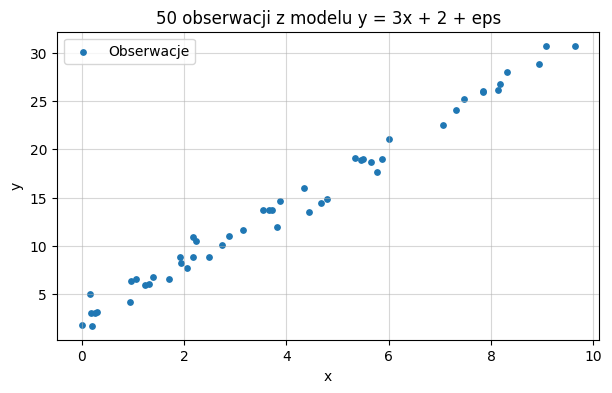

In [76]:
plt.figure(figsize=(7,4))
plt.scatter(x.numpy(), y.numpy(), s=15, label="Obserwacje") 
plt.xlabel("x")
plt.ylabel("y")
plt.title("50 obserwacji z modelu y = 3x + 2 + eps")
plt.legend()
plt.grid(alpha=0.5)
plt.show()

### Zadanie 2


* Wygeneruj trójwymiarowy tensor o kształcie `(B, T, C)` reprezentujący dane z czujników (Batch, Time, Channels), zawierający losowy szum oraz brakujące wartości (`NaN`).
* Napisasz funkcję, która w sposób efektywny (najlepiej bez używania pętli `for` w Pythonie) zastąpi wartości `NaN` średnią kroczącą z sąsiednich kroków czasowych dla każdego kanału osobno.
* Dodaj krok augmentacji polegający na losowym przesunięciu w czasie (roll) oraz losowym skalowaniu amplitudy sygnału.

In [95]:
import math
import torch.nn.functional as F

torch.manual_seed(42)
B, T, C = 4, 100, 3

# 1) Sygnał: trzy "czujniki" (sinus, cosinus, sinus o podwójnej częstotliwości) + szum
t = torch.linspace(0, 4 * math.pi, T)
sygnal = torch.stack([torch.sin(t), torch.cos(t), torch.sin(2 * t)], dim=-1)   # (T, C)
dane = sygnal.unsqueeze(0).repeat(B, 1, 1) + 0.1 * torch.randn(B, T, C)       # (B, T, C)
maska_nan = torch.rand(B, T, C) < 0.2                                          # ok. 10% braków
dane[maska_nan] = float("nan")
print("liczba NaN:", torch.isnan(dane).sum().item())

liczba NaN: 230


In [96]:
# 2) Uzupełnianie NaN średnią kroczącą (bez pętli for)
def uzupelnij_nan(x, okno=5):
    # okno musi być nieparzyste, żeby długość sygnału się nie zmieniła
    B, T, C = x.shape
    nan = torch.isnan(x)
    wartosci = torch.where(nan, torch.zeros_like(x), x)        # NaN -> 0 (nie wpływa na sumę)
    obecne = (~nan).float()                                     # 1 = wartość znana, 0 = brak

    # (B, T, C) -> (B*C, 1, T): każdy kanał każdego przykładu jako osobny sygnał 1D
    wartosci = wartosci.permute(0, 2, 1).reshape(B * C, 1, T)
    obecne = obecne.permute(0, 2, 1).reshape(B * C, 1, T)

    jadro = torch.ones(1, 1, okno)                              # filtr sumujący okno
    suma = F.conv1d(wartosci, jadro, padding=okno // 2)         # suma znanych wartości w oknie
    licznik = F.conv1d(obecne, jadro, padding=okno // 2)        # ile znanych wartości w oknie

    srednia = (suma / licznik.clamp(min=1)).reshape(B, C, T).permute(0, 2, 1)
    licznik = licznik.reshape(B, C, T).permute(0, 2, 1)

    # gdy w całym oknie nie ma żadnej znanej wartości - średnia kanału z całego przebiegu
    srednia_kanalu = torch.nanmean(x, dim=1, keepdim=True).expand_as(x)
    zastepstwo = torch.where(licznik > 0, srednia, srednia_kanalu)
    return torch.where(nan, zastepstwo, x)

dane_uzup = uzupelnij_nan(dane)
print("NaN po uzupełnieniu:", torch.isnan(dane_uzup).sum().item())

NaN po uzupełnieniu: 0


In [97]:
# 3) Augmentacja: losowe przesunięcie w czasie (roll) i losowe skalowanie amplitudy
def augmentuj(x, max_przesuniecie=10, skala=(0.8, 1.2)):
    B, T, C = x.shape
    przes = torch.randint(-max_przesuniecie, max_przesuniecie + 1, (B,))   # osobne przesunięcie dla każdego przykładu
    # roll bez pętli: indeks wyjścia i bierze wartość z pozycji (i - przesunięcie) mod T
    idx = (torch.arange(T).unsqueeze(0) - przes.unsqueeze(1)) % T          # (B, T)
    przesuniete = torch.gather(x, 1, idx.unsqueeze(-1).expand(-1, -1, C))  # (B, T, C)
    wspolczynniki = torch.empty(B, 1, C).uniform_(*skala)                  # osobna skala dla przykładu i kanału
    return przesuniete * wspolczynniki, przes, wspolczynniki


dane_aug, przes, wsp = augmentuj(dane_uzup)
print("przesunięcia:", przes.tolist())

przesunięcia: [-3, 10, 5, -6]


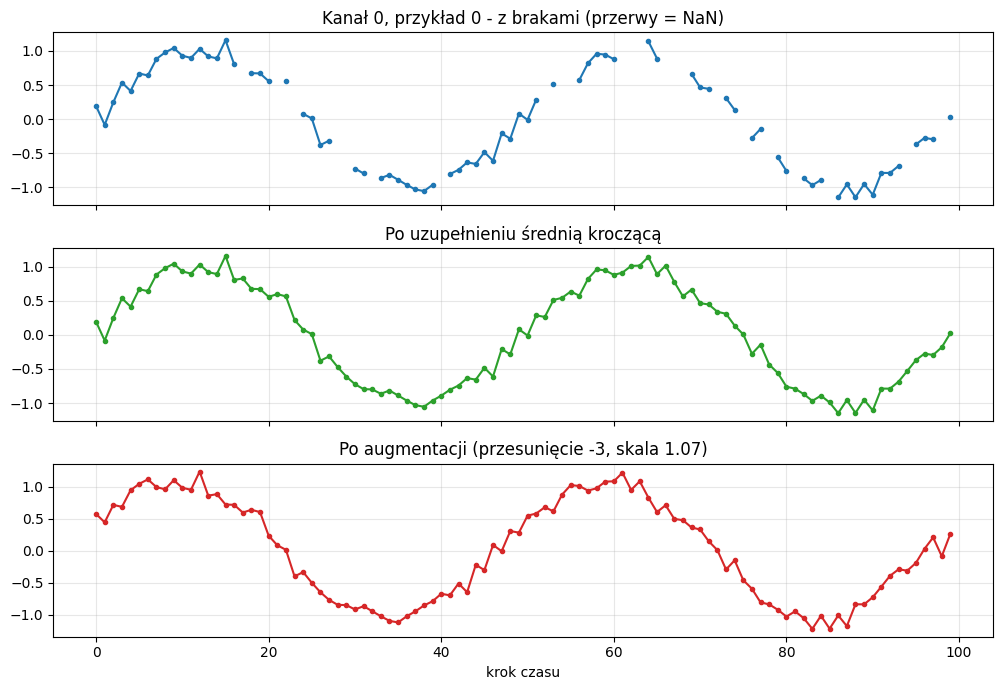

In [98]:
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
ax[0].plot(dane[0, :, 0].numpy(), "o-", ms=3); ax[0].set_title("Kanał 0, przykład 0 - z brakami (przerwy = NaN)")
ax[1].plot(dane_uzup[0, :, 0].numpy(), "o-", ms=3, color="tab:green"); ax[1].set_title("Po uzupełnieniu średnią kroczącą")
ax[2].plot(dane_aug[0, :, 0].numpy(), "o-", ms=3, color="tab:red")
ax[2].set_title(f"Po augmentacji (przesunięcie {przes[0].item()}, skala {wsp[0, 0, 0].item():.2f})")
ax[2].set_xlabel("krok czasu")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Zadanie 3

* Zaimportuj dowolny obraz jako tensor o kształcie `(C, H, W)`.
* Podziel obraz na siatkę nienakładających się bloków o rozmiarze `p x p` (np. `16x16`), przekształcając tensor do kształtu `(N, C * p * p)`, gdzie `N` to liczba bloków.
* Wykonaj losową permutację kolejności bloków , a następnie odtwórz zniekształcony obraz z powrotem do oryginalnego kształtu `(C, H, W)`. Wyświetl wynik.


In [105]:
from skimage import data          # skimage jest w Colab; zawiera przykładowe zdjęcia

p = 16
obraz_np = data.rocket()                                 # (512, 512, 3), uint8
obraz = torch.from_numpy(obraz_np).permute(2, 0, 1).float() / 255.0   # (C, H, W) w [0, 1]
C, H, W = obraz.shape
H, W = H - H % p, W - W % p                                       # przycięcie do wielokrotności p
obraz = obraz[:, :H, :W]
nH, nW = H // p, W // p

# Podział na bloki: (C, H, W) -> (C, nH, nW, p, p) -> (N, C*p*p)
bloki = obraz.unfold(1, p, p).unfold(2, p, p)                     # (C, nH, nW, p, p)
bloki = bloki.permute(1, 2, 0, 3, 4).reshape(nH * nW, C * p * p)  # (N, C*p*p)
print("bloki:", tuple(bloki.shape))

bloki: (1040, 768)


In [107]:
def zloz(bloki):
    # (N, C*p*p) -> (nH, nW, C, p, p) -> (C, nH, p, nW, p) -> (C, H, W)
    return bloki.reshape(nH, nW, C, p, p).permute(2, 0, 3, 1, 4).reshape(C, H, W)


assert torch.equal(zloz(bloki), obraz)                            # bez permutacji wracamy do oryginału


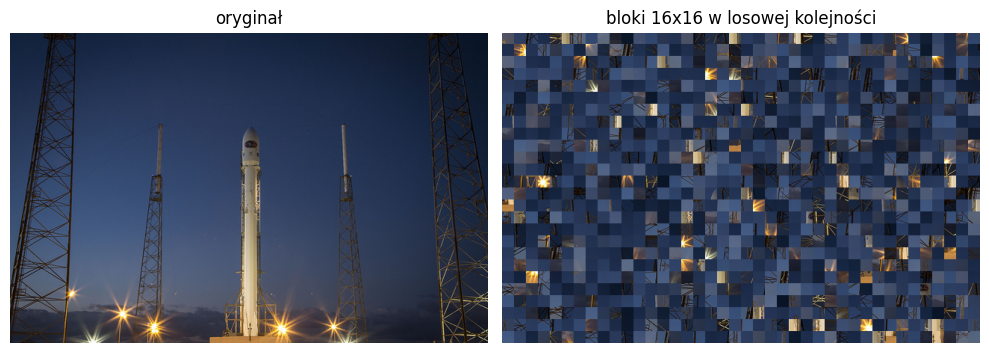

In [108]:
torch.manual_seed(42)
perm = torch.randperm(nH * nW)                                    # losowa kolejność bloków
obraz_tasowany = zloz(bloki[perm])

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(obraz.permute(1, 2, 0).numpy()); ax[0].set_title("oryginał")
ax[1].imshow(obraz_tasowany.permute(1, 2, 0).numpy()); ax[1].set_title(f"bloki {p}x{p} w losowej kolejności")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### Zadanie 4

* Utwórz rzadki tensor (`torch.sparse_coo_tensor`) reprezentujący macierz interakcji użytkownik-produkt o wymiarach `1000 x 1000` z gęstością zapełnienia na poziomie 0.1%.
* Przekonwertuj go na format CSR (`torch.sparse_csr_tensor`).
* Oblicz średnią ocen dla każdego użytkownika oraz zaimplementuj efektywne filtrowanie użytkowników, którzy ocenili mniej niż 5 produktów, zwracając przefiltrowany tensor rzadki.
* Przetestuj też inne operacje jakimi możemy poddać tensory rzadkie


In [109]:
n_u, n_p = 1000, 1000
nnz = int(0.001 * n_u * n_p)                            # 0.1% z miliona = 1000 ocen
g = torch.Generator().manual_seed(42)

# Aktywność użytkowników jak w realnych systemach: kilku bardzo aktywnych, wielu prawie nieaktywnych
wagi = 1.0 / torch.arange(1, n_u + 1).float()
u = torch.multinomial(wagi, nnz, replacement=True, generator=g)
pr = torch.randint(0, n_p, (nnz,), generator=g)
lin = torch.unique(u * n_p + pr)                        # usuwamy powtórzone pary (użytkownik, produkt)
wiersze, kolumny = lin // n_p, lin % n_p
oceny = torch.randint(1, 6, (len(lin),), generator=g).float()   # oceny 1-5

R = torch.sparse_coo_tensor(torch.stack([wiersze, kolumny]), oceny, size=(n_u, n_p)).coalesce()
print("niezerowe:", R._nnz(), "| gęstość:", R._nnz() / (n_u * n_p))

niezerowe: 986 | gęstość: 0.000986


C:\Users\diepl\AppData\Local\Temp\ipykernel_28372\1290393187.py:13: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  R = torch.sparse_coo_tensor(torch.stack([wiersze, kolumny]), oceny, size=(n_u, n_p)).coalesce()


In [110]:
# Konwersja do CSR (dwa sposoby: metoda i jawny konstruktor)
R_csr = R.to_sparse_csr()
R_csr2 = torch.sparse_csr_tensor(R_csr.crow_indices(), R_csr.col_indices(), R_csr.values(), size=R_csr.shape)
print("CSR identyczny:", torch.equal(R_csr.to_dense(), R_csr2.to_dense()))

CSR identyczny: True


C:\Users\diepl\AppData\Local\Temp\ipykernel_28372\2300325101.py:2: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\SparseCsrTensorImpl.cpp:51.)
  R_csr = R.to_sparse_csr()


In [111]:
# Średnia ocen per użytkownik
liczba_ocen = torch.bincount(R.indices()[0], minlength=n_u)          # z COO
liczba_ocen_csr = R_csr.crow_indices().diff()                         # z CSR - różnice wskaźników wierszy
assert torch.equal(liczba_ocen, liczba_ocen_csr)
suma_ocen = torch.sparse.sum(R, dim=1).to_dense()
srednia = torch.where(liczba_ocen > 0, suma_ocen / liczba_ocen.clamp(min=1), torch.tensor(float("nan")))
print("średnie 5 najaktywniejszych:", srednia[:5].round(decimals=2).tolist())

średnie 5 najaktywniejszych: [3.2200000286102295, 3.069999933242798, 3.369999885559082, 3.0299999713897705, 2.640000104904175]


In [113]:
# Filtrowanie: zostają tylko oceny użytkowników z >= 5 ocenami
def filtruj_uzytkownikow(R, min_ocen=5):
    idx, val = R.indices(), R.values()
    liczba = torch.bincount(idx[0], minlength=R.shape[0])
    zostaw = liczba[idx[0]] >= min_ocen                   # maska po niezerowych elementach
    return torch.sparse_coo_tensor(idx[:, zostaw], val[zostaw], size=R.shape).coalesce()

R_f = filtruj_uzytkownikow(R)
print("użytkownicy >= 5 ocen:", (liczba_ocen >= 5).sum().item(), "| ocen po filtrze:", R_f._nnz())

użytkownicy >= 5 ocen: 39 | ocen po filtrze: 588


In [114]:
# Inne operacje na tensorach rzadkich
wektor = torch.ones(n_p, 1)
print("R @ wektor (suma ocen):", torch.sparse.mm(R, wektor)[:3].ravel().tolist())
print("transpozycja:", R.t().shape)
print("R * 2, R + R:", (R * 2)._nnz(), (R + R).coalesce()._nnz())
podobienstwo = torch.sparse.mm(R.t(), R)                  # produkt x produkt (współwystępowanie)
print("macierz podobieństwa produktów - niezerowych:", podobienstwo._nnz())
print("fragment gęsto:\n", R.to_dense()[:3, :8])
pamiec_gesta = n_u * n_p * 4
pamiec_rzadka = R._nnz() * (2 * 8 + 4)                     # dwa indeksy int64 + wartość float32
print(f"pamięć: gęsta {pamiec_gesta / 1e6:.1f} MB vs rzadka {pamiec_rzadka / 1e3:.1f} kB")

R @ wektor (suma ocen): [448.0, 181.0, 165.0]
transpozycja: torch.Size([1000, 1000])
R * 2, R + R: 986 986
macierz podobieństwa produktów - niezerowych: 30381
fragment gęsto:
 tensor([[0., 0., 0., 0., 0., 0., 0., 5.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 5., 0., 0., 0., 0., 0.]])
pamięć: gęsta 4.0 MB vs rzadka 19.7 kB
